# Default vs inference-only standardization (n=100)

This notebook compares the available n=100 Default and Inference-only standardization runs.
S=4D plots appear first, followed by S=2D. Each pair retains L2 and Density
diagnostics, the three error metrics, M1–M12 source colors, and circle markers.
No-standardization comparison data are not available for n=100 yet.


In [2]:
from io import BytesIO
from importlib import reload
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "examples/gaussian/config.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Pick up edits to plot.py when rerunning this notebook in an existing kernel.
from examples.gaussian.analysis import plot
reload(plot)
from examples.gaussian.analysis.plot import KEYS, load_runs, plot_metric_grid

RESULT_DIR = ROOT / "examples/gaussian/results"
RESULT_DIRS = {
    "Default": RESULT_DIR,
    "Inference-only standardization": RESULT_DIR / "ablation/inference_only",
}
all_runs = {
    setting: load_runs("indirect", 100, summary_dims=(40, 80), result_dir=directory)
    for setting, directory in RESULT_DIRS.items()
}

for runs in all_runs.values():
    for label, frame in runs.items():
        baseline = all_runs["Default"][label].set_index(KEYS).sort_index()
        paired = frame.set_index(KEYS).sort_index()
        pd.testing.assert_frame_equal(
            baseline[["gold_logml", "gold_pmp"]],
            paired[["gold_logml", "gold_pmp"]], check_exact=True,
        )
print("Paired dataset keys and gold standards match for S=2D and S=4D.")

Paired dataset keys and gold standards match for S=2D and S=4D.


In [3]:
# logML is plotted in log10 units. Use one range that covers both settings
# and both summary dimensions, so paired panels remain directly comparable.
logml_columns = ["signed_logml_error", "logml_error_lower", "logml_error_upper"]
logml_values = pd.concat(
    [frame[logml_columns] for runs in all_runs.values() for frame in runs.values()],
    ignore_index=True,
).to_numpy(float) / np.log(10.)
logml_min, logml_max = float(logml_values.min()), float(logml_values.max())
logml_ylim = (
    -10. ** np.ceil(np.log10(max(1., -logml_min))),
     10. ** np.ceil(np.log10(max(1., logml_max))),
)
Y_AXIS = {
    "posterior_mmd": dict(yscale="linear", ylim=(0., 1.5)),
    "logml": dict(yscale="symlog", linthresh=1., linscale=.9, ylim=logml_ylim),
    "pmp": dict(yscale="linear", ylim=(-1.05, 1.05)),
}
OUTPUT_DIR = RESULT_DIR / "plots/n100"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def show_pair(setting, metric, summary_dim=80):
    summary = {40: "2D", 80: "4D"}[summary_dim]
    run_label = f"S={summary}"
    output_dir = OUTPUT_DIR / f"standardization_s{summary.lower()}"
    output_dir.mkdir(parents=True, exist_ok=True)
    panels = []
    for label in ("Default", setting):
        fig, _ = plot_metric_grid(
            {run_label: all_runs[label][run_label]}, metric, diagnostics=("l2", "density"),
            color_by="source", source_marker="o", figsize=(14, 20), **Y_AXIS[metric],
        )
        try:
            fig.suptitle(label, y=1.015, fontsize=24)
            with BytesIO() as buffer:
                fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
                with PILImage.open(buffer) as image:
                    panels.append(image.convert("RGB"))
        finally:
            plt.close(fig)
    pair = PILImage.new("RGB", (sum(p.width for p in panels) + 24,
                               max(p.height for p in panels)), "white")
    x = 0
    for panel in panels:
        pair.paste(panel, (x, 0))
        x += panel.width + 24
        panel.close()
    output = output_dir / f"default_vs_{RESULT_DIRS[setting].name}_{metric}.png"
    pair.save(output, dpi=(120, 120))
    pair.close()
    display(Image(filename=str(output), width=1400))
    print(f"Saved: {output}")

## S=4D

### Posterior MMD

#### Default vs Inference-only standardization

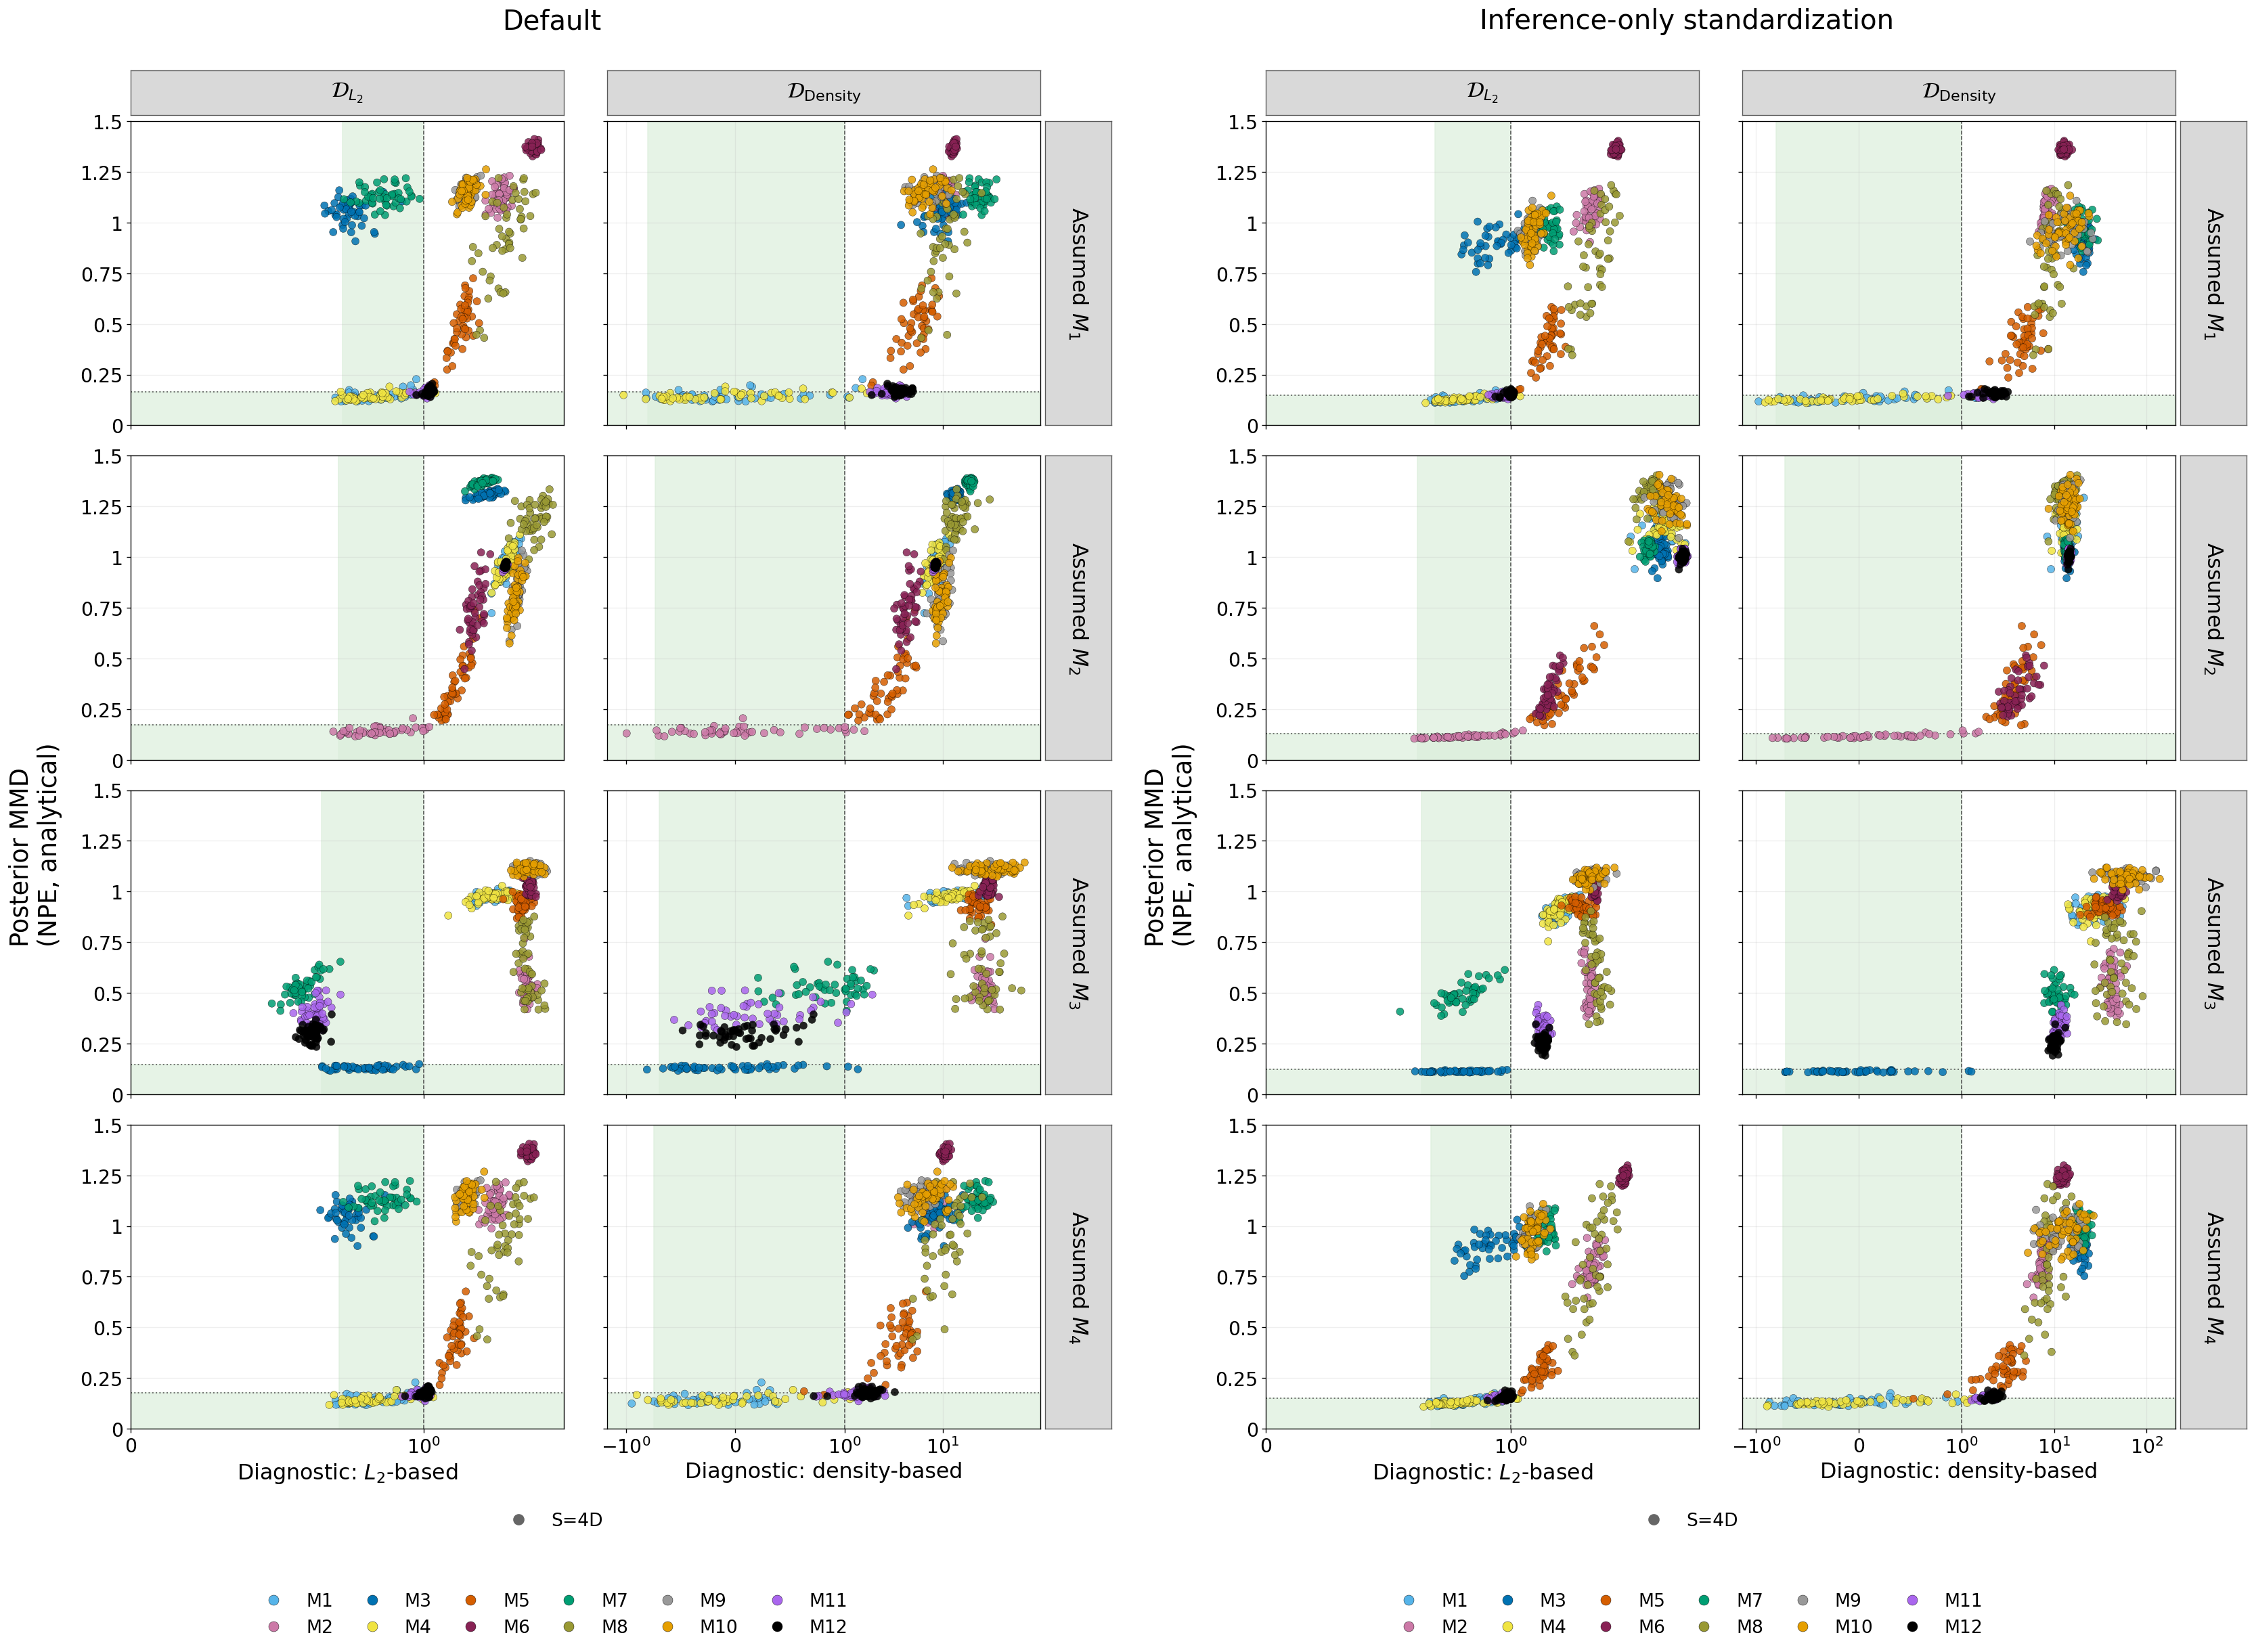

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/n100/standardization_s4d/default_vs_inference_only_posterior_mmd.png


In [4]:
show_pair("Inference-only standardization", "posterior_mmd")

### Log10 marginal-likelihood error

#### Default vs Inference-only standardization

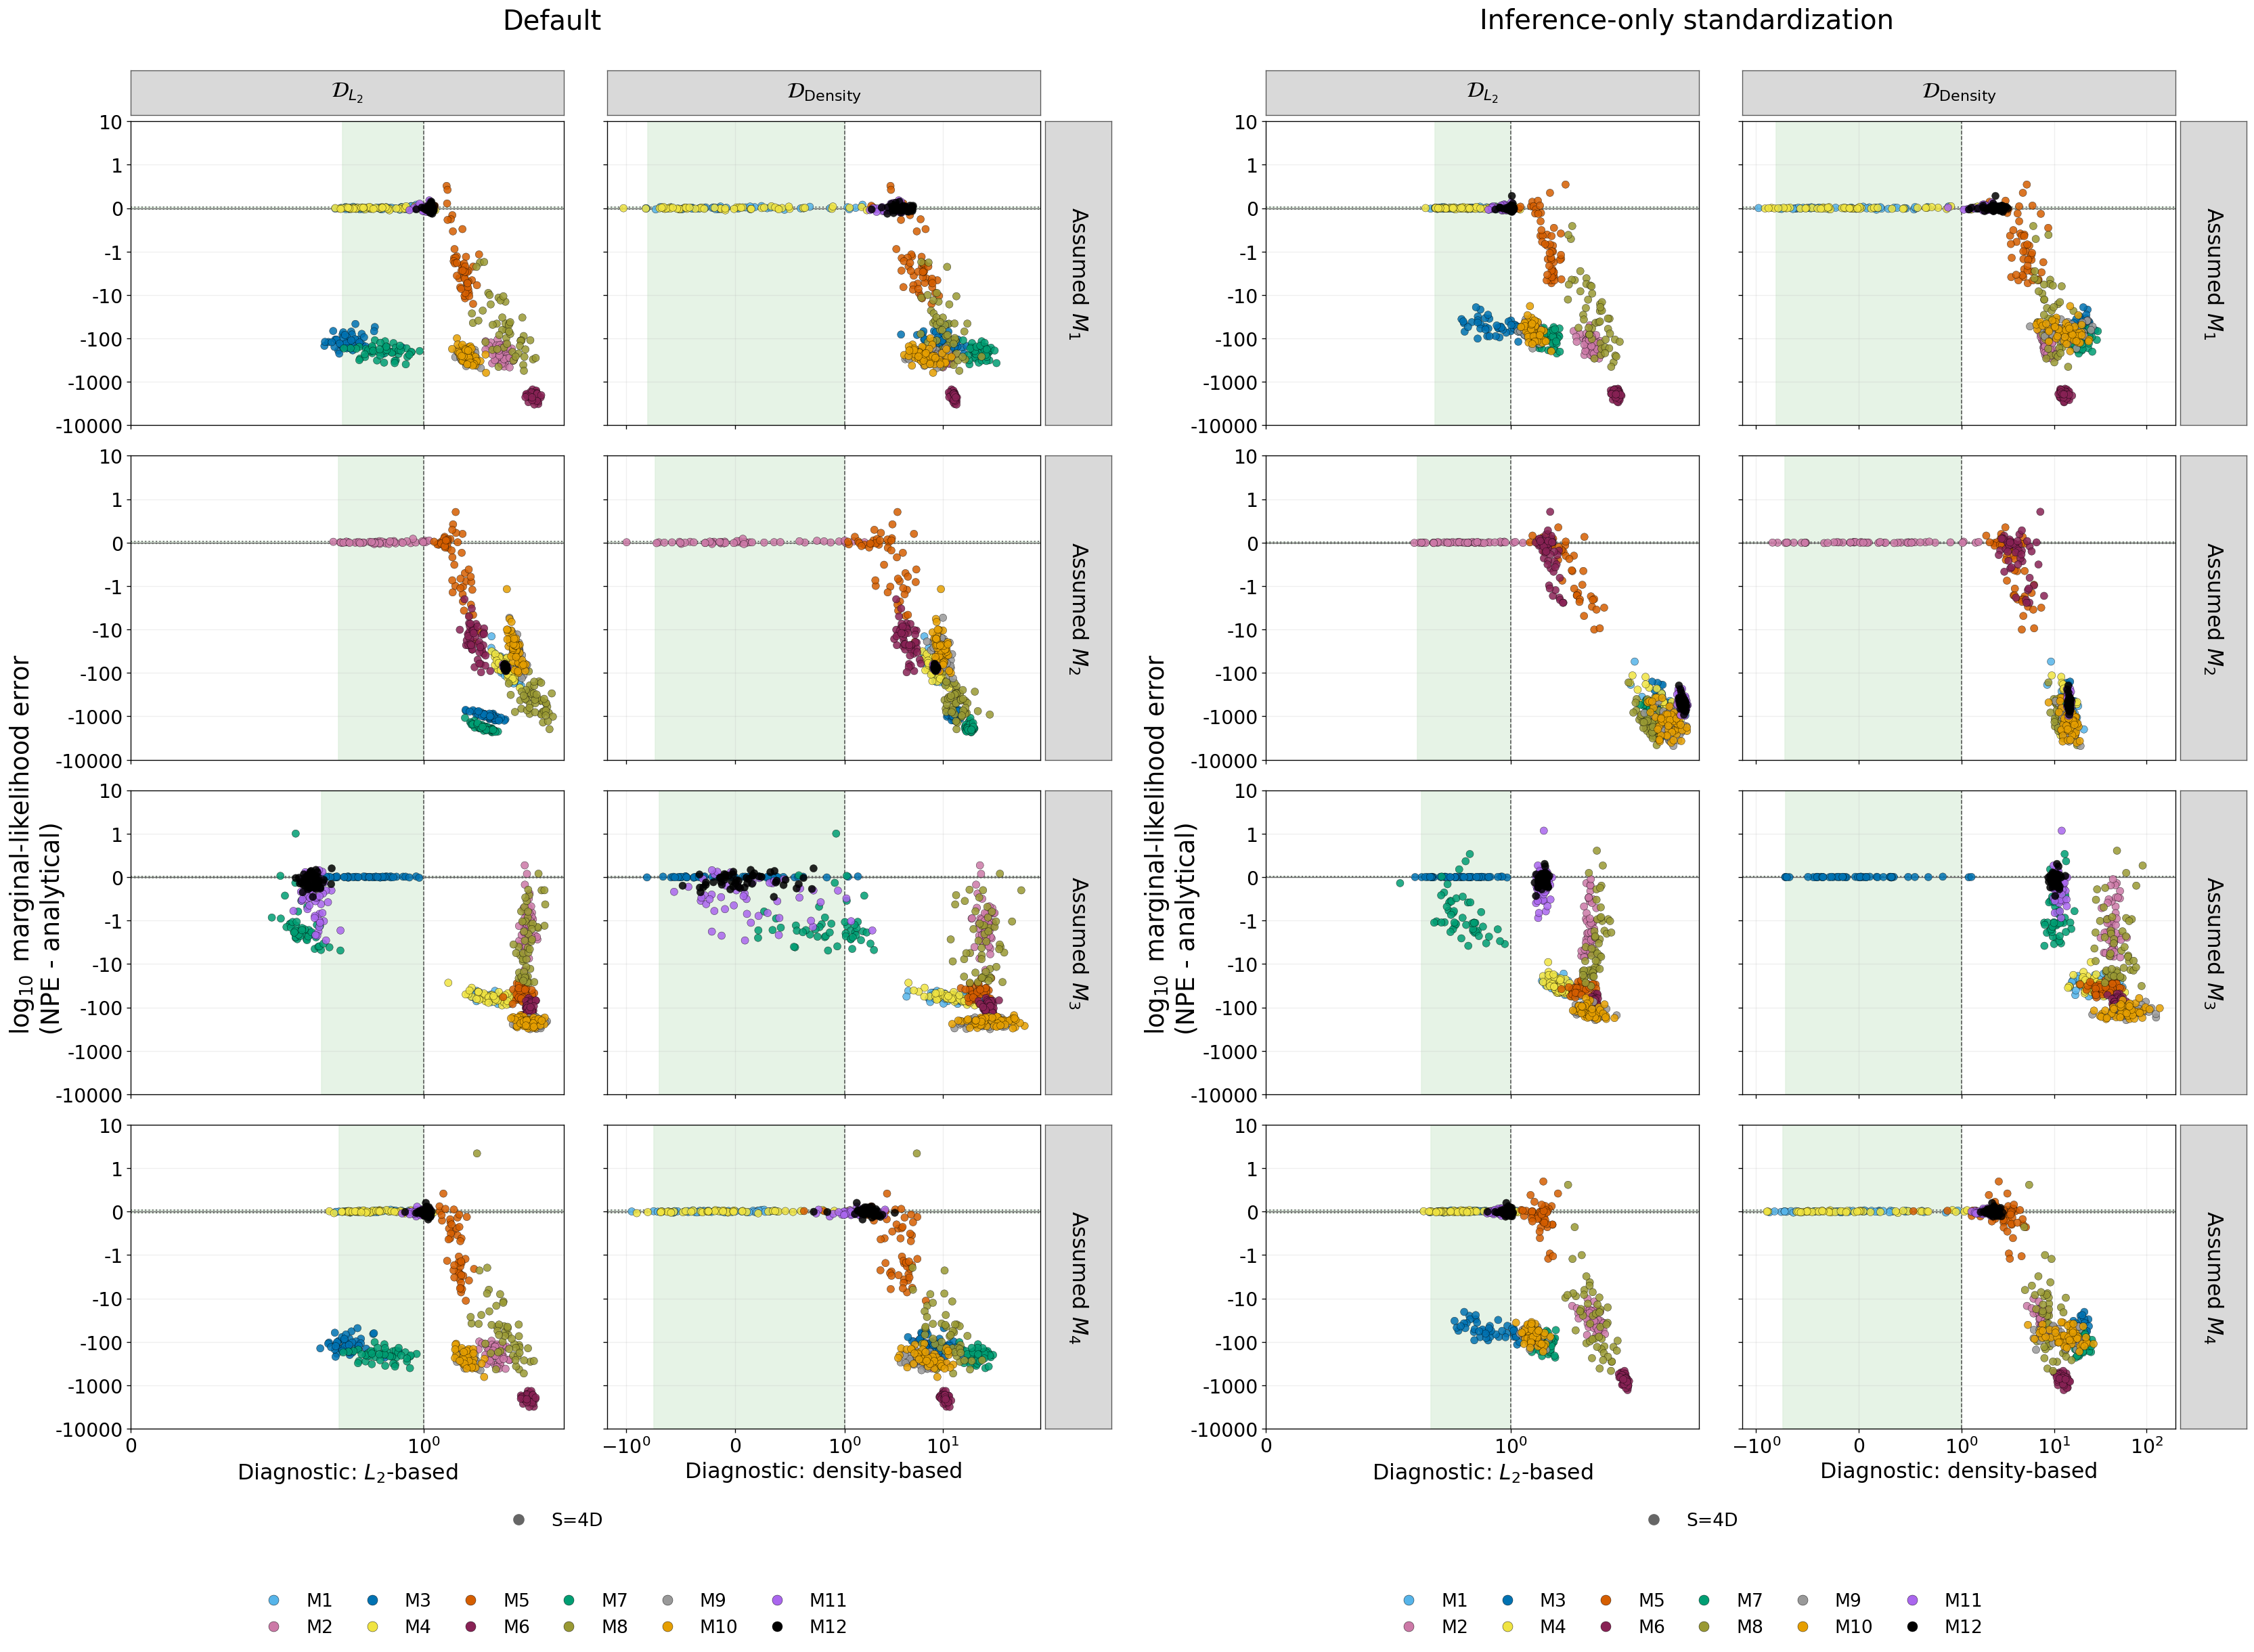

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/n100/standardization_s4d/default_vs_inference_only_logml.png


In [5]:
show_pair("Inference-only standardization", "logml")

### PMP error

#### Default vs Inference-only standardization

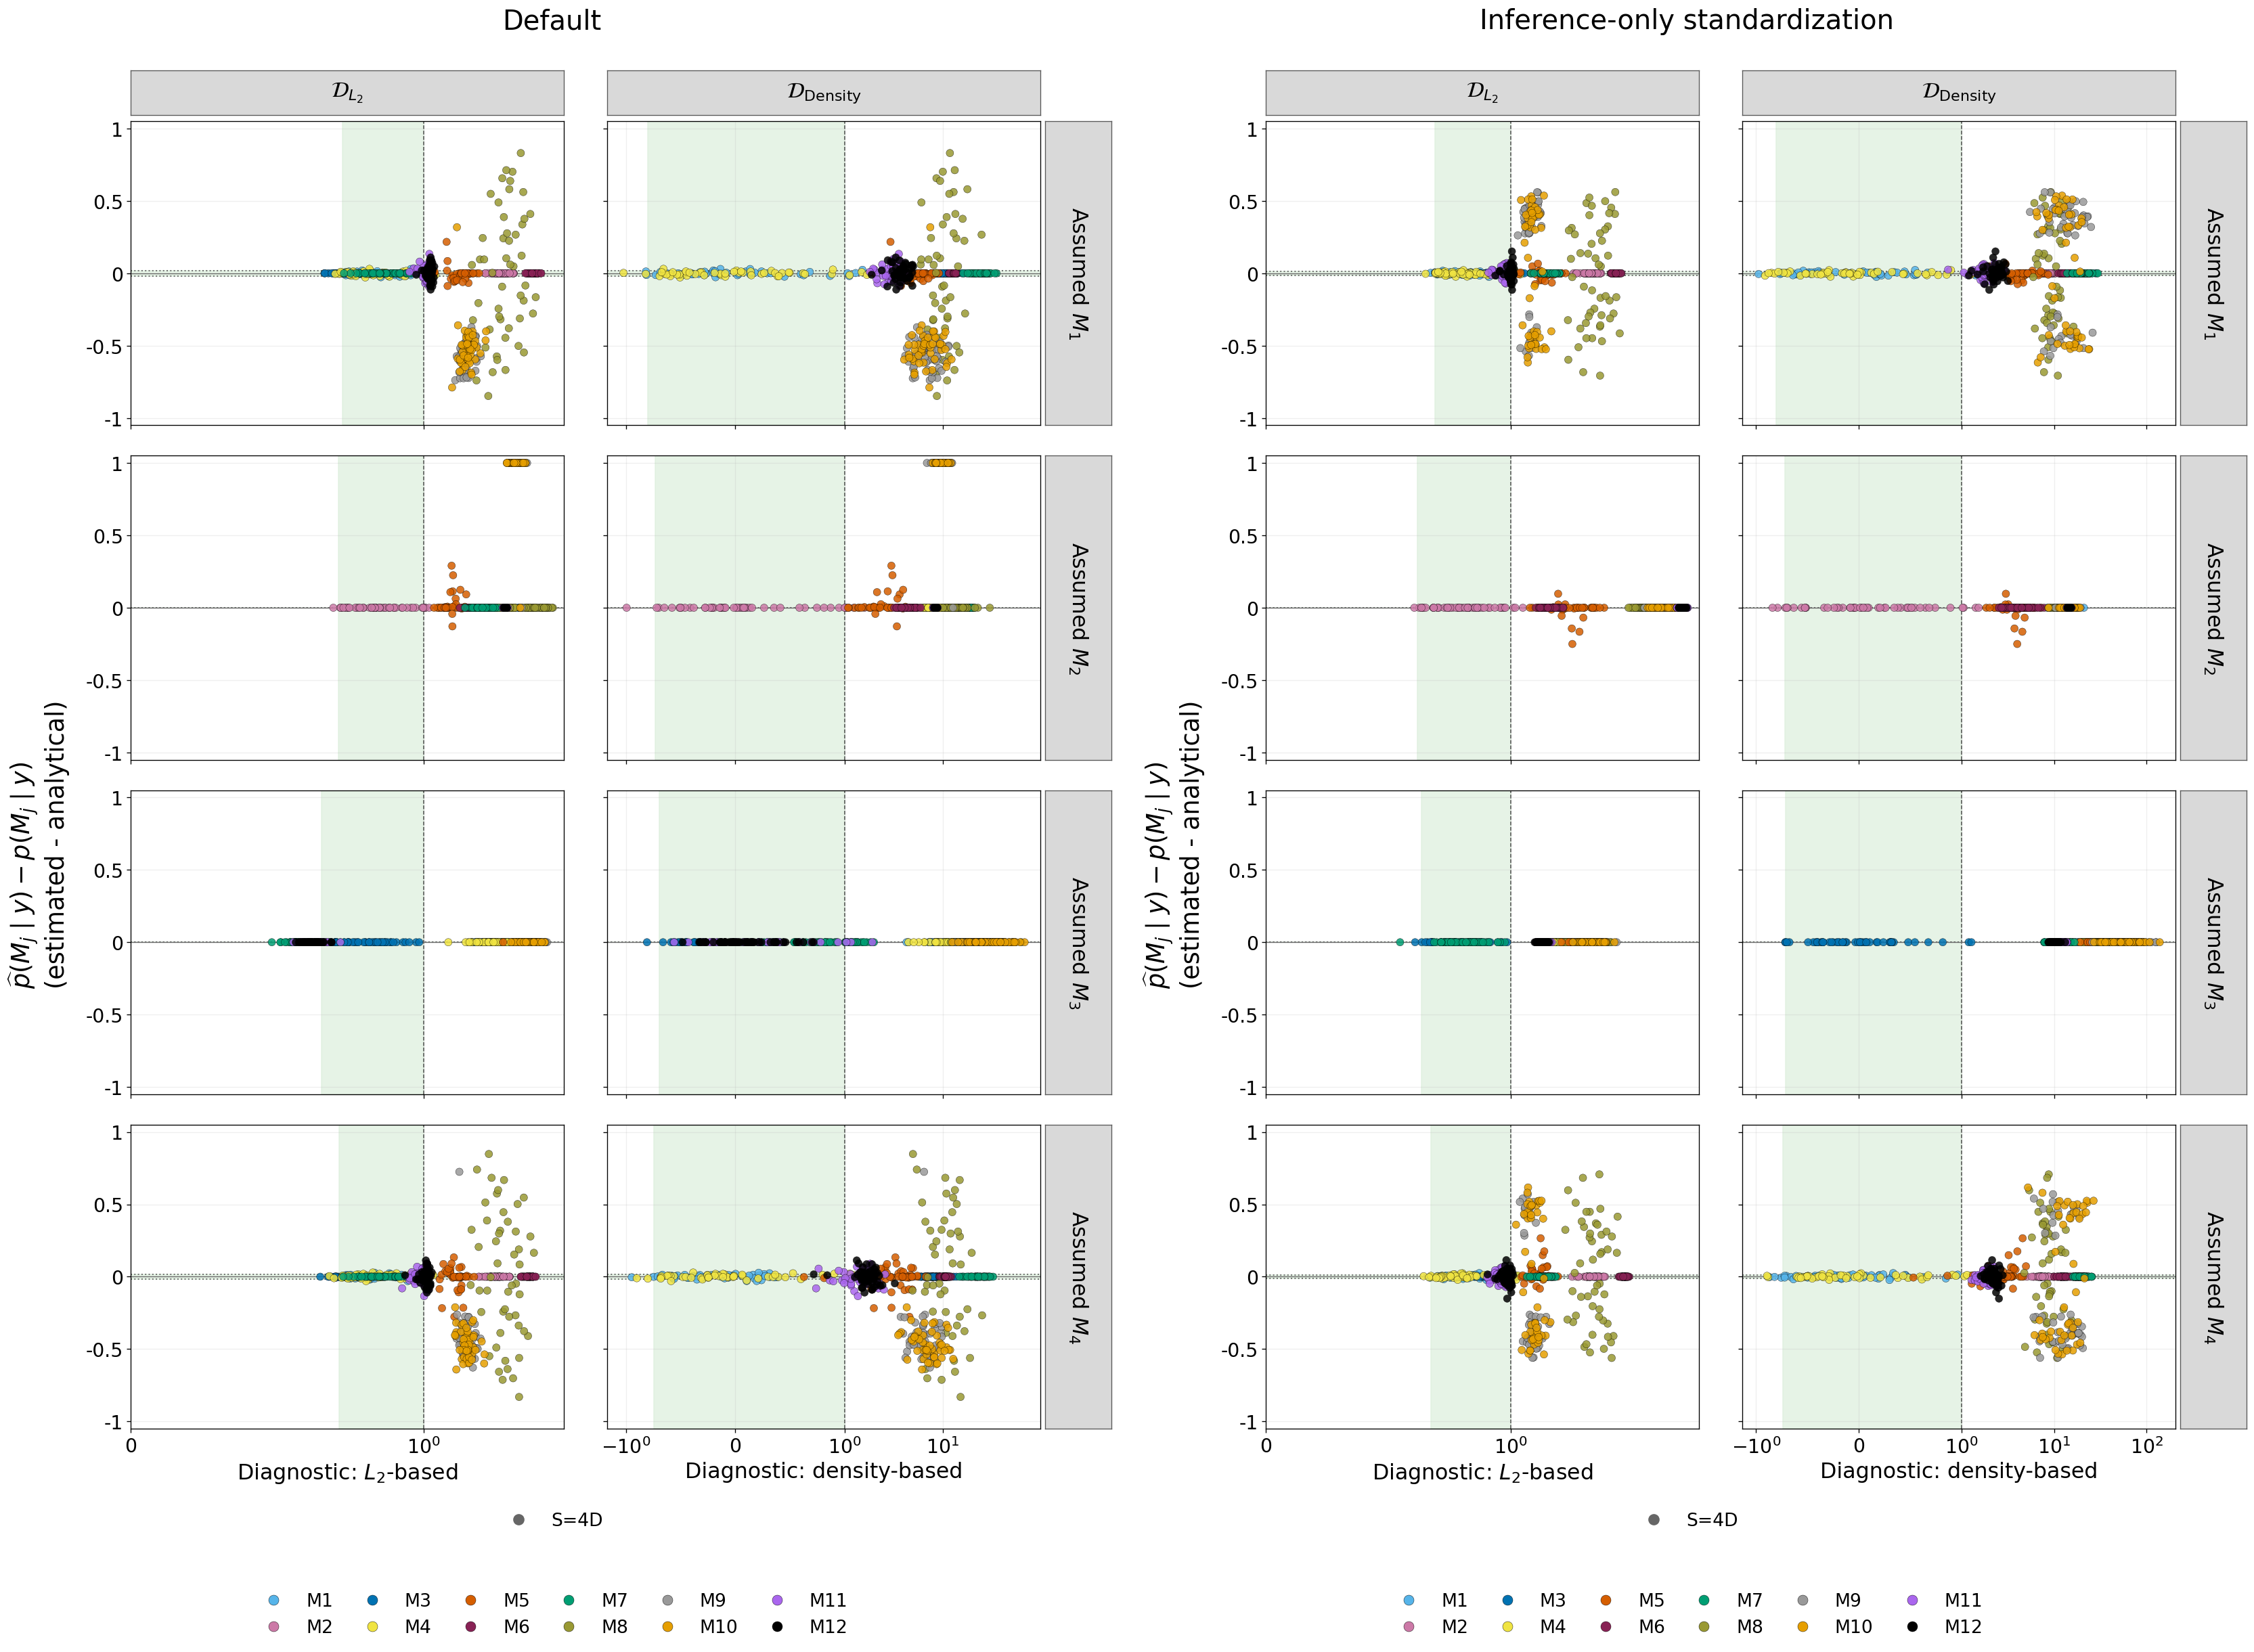

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/n100/standardization_s4d/default_vs_inference_only_pmp.png


In [6]:
show_pair("Inference-only standardization", "pmp")

## S=2D

### Posterior MMD

#### Default vs Inference-only standardization

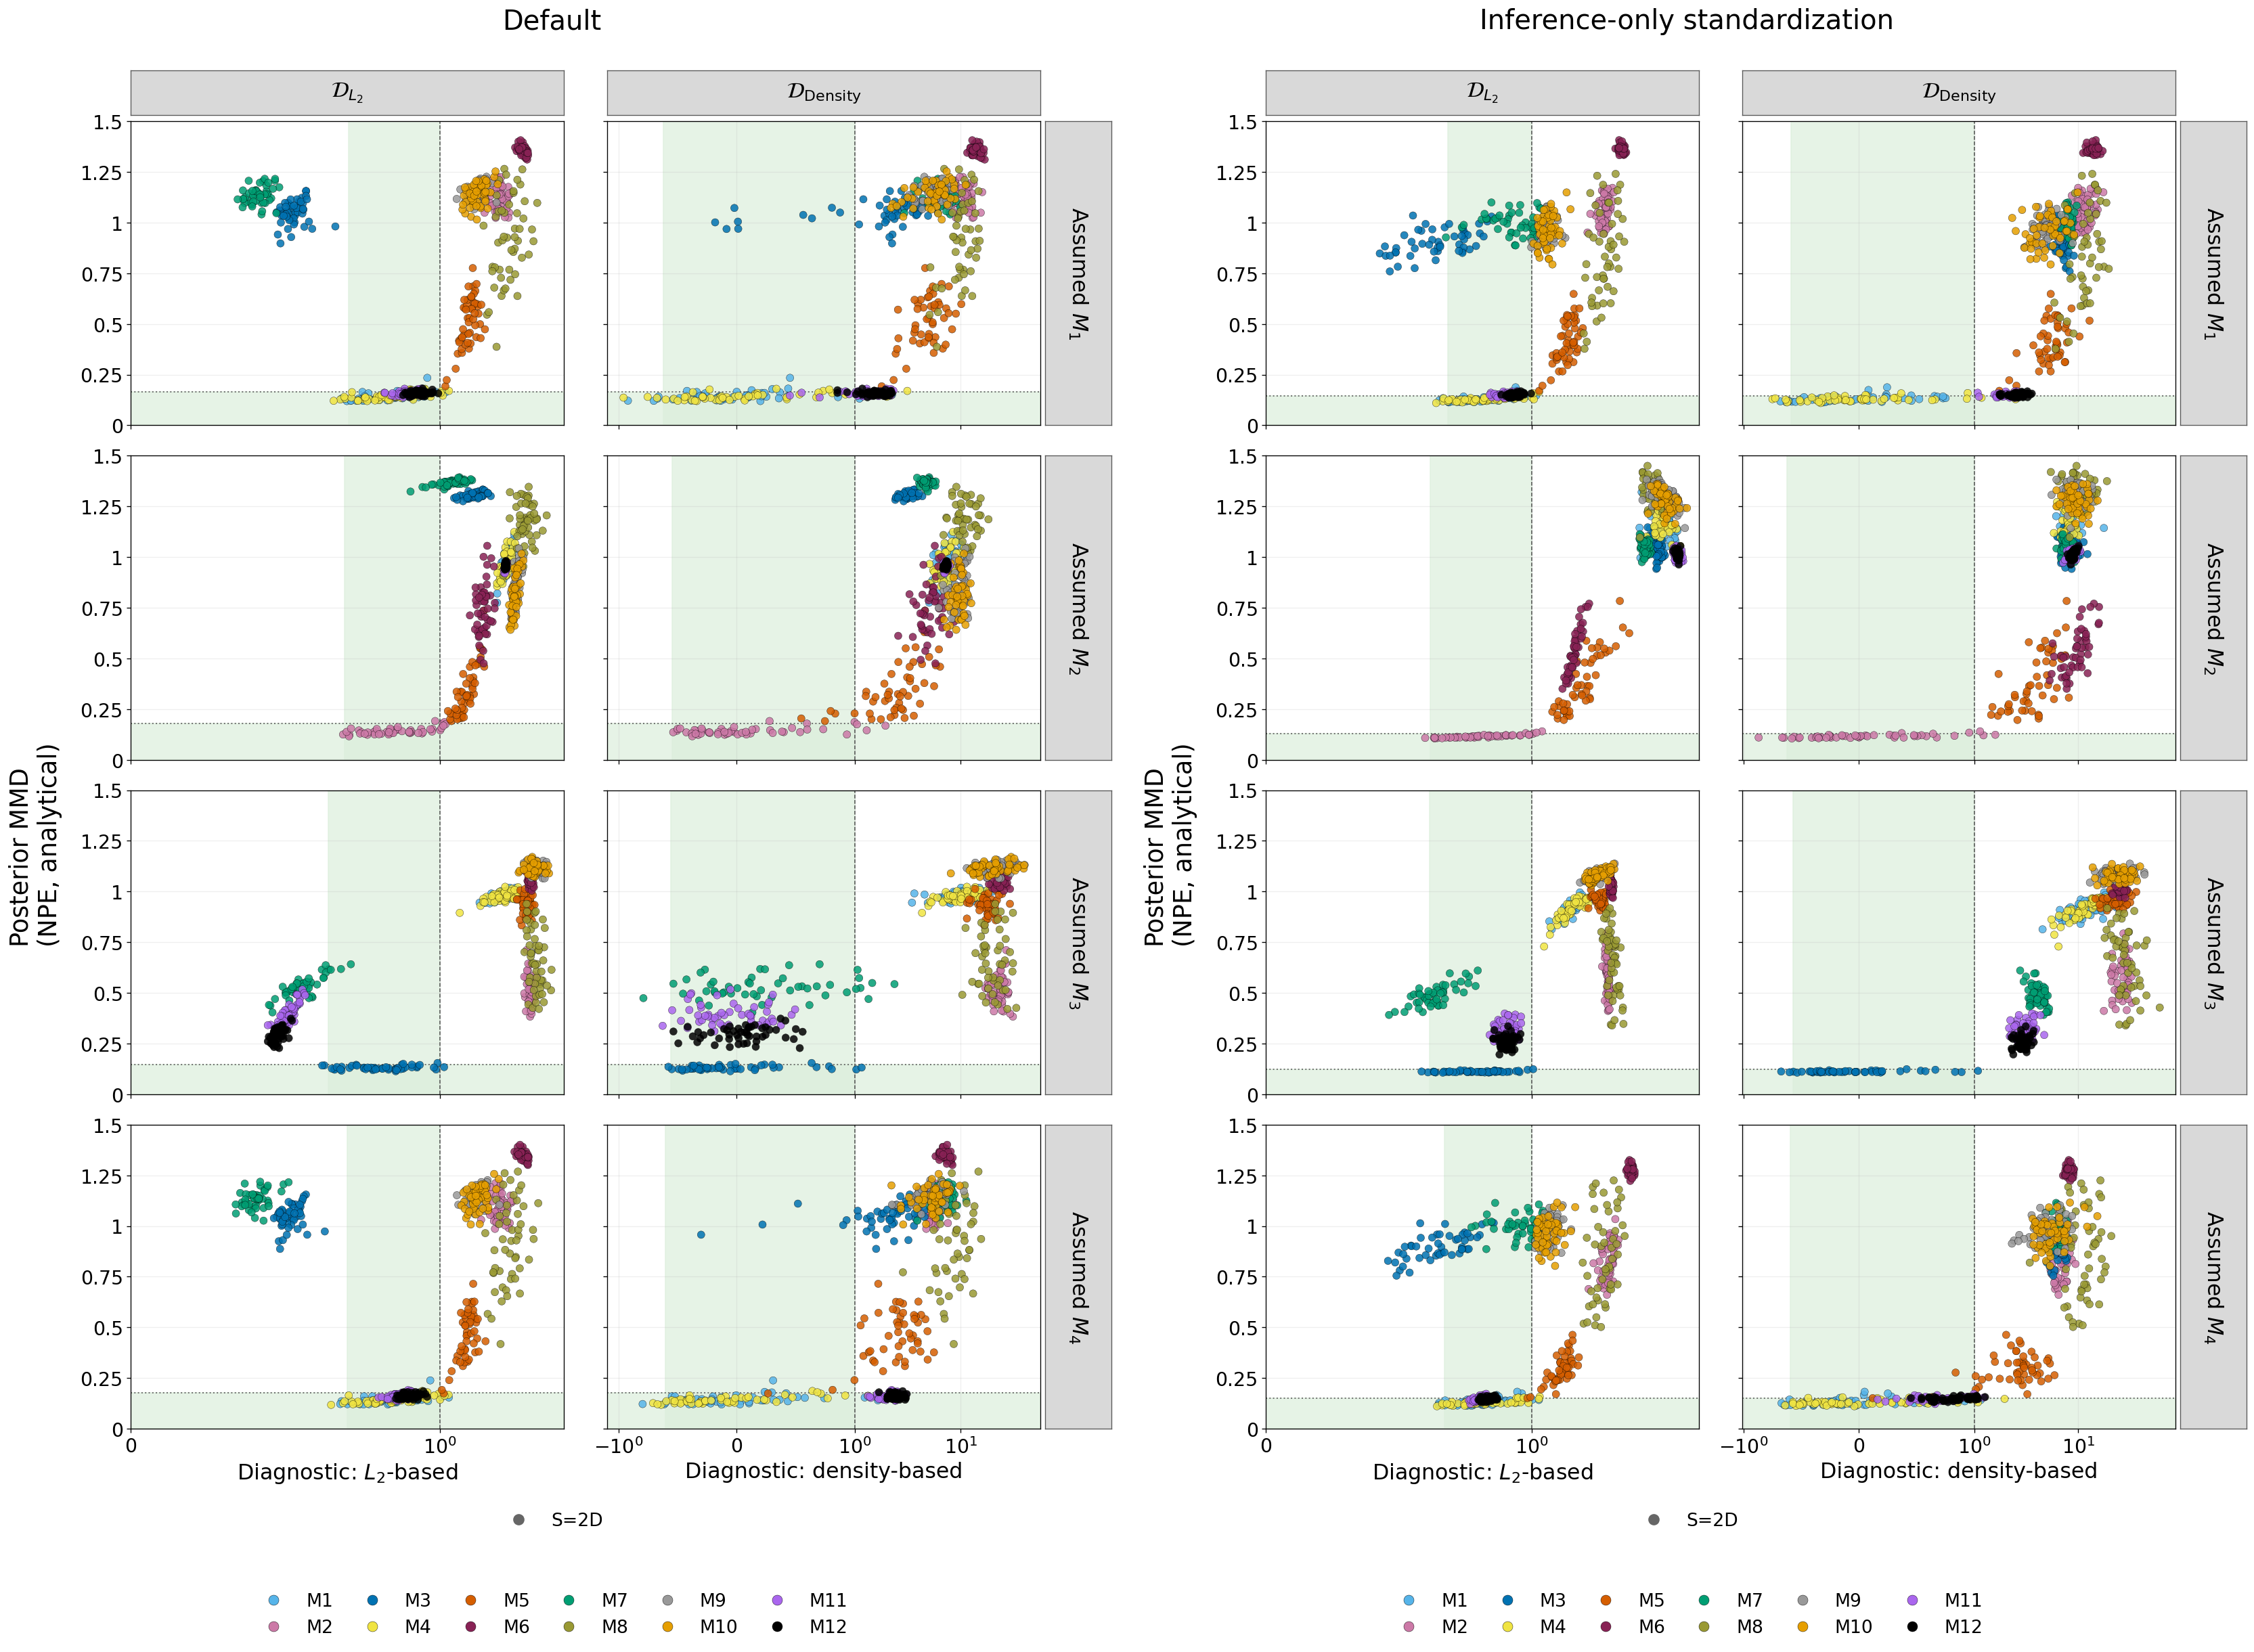

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/n100/standardization_s2d/default_vs_inference_only_posterior_mmd.png


In [7]:
show_pair("Inference-only standardization", "posterior_mmd", summary_dim=40)

### Log10 marginal-likelihood error

#### Default vs Inference-only standardization

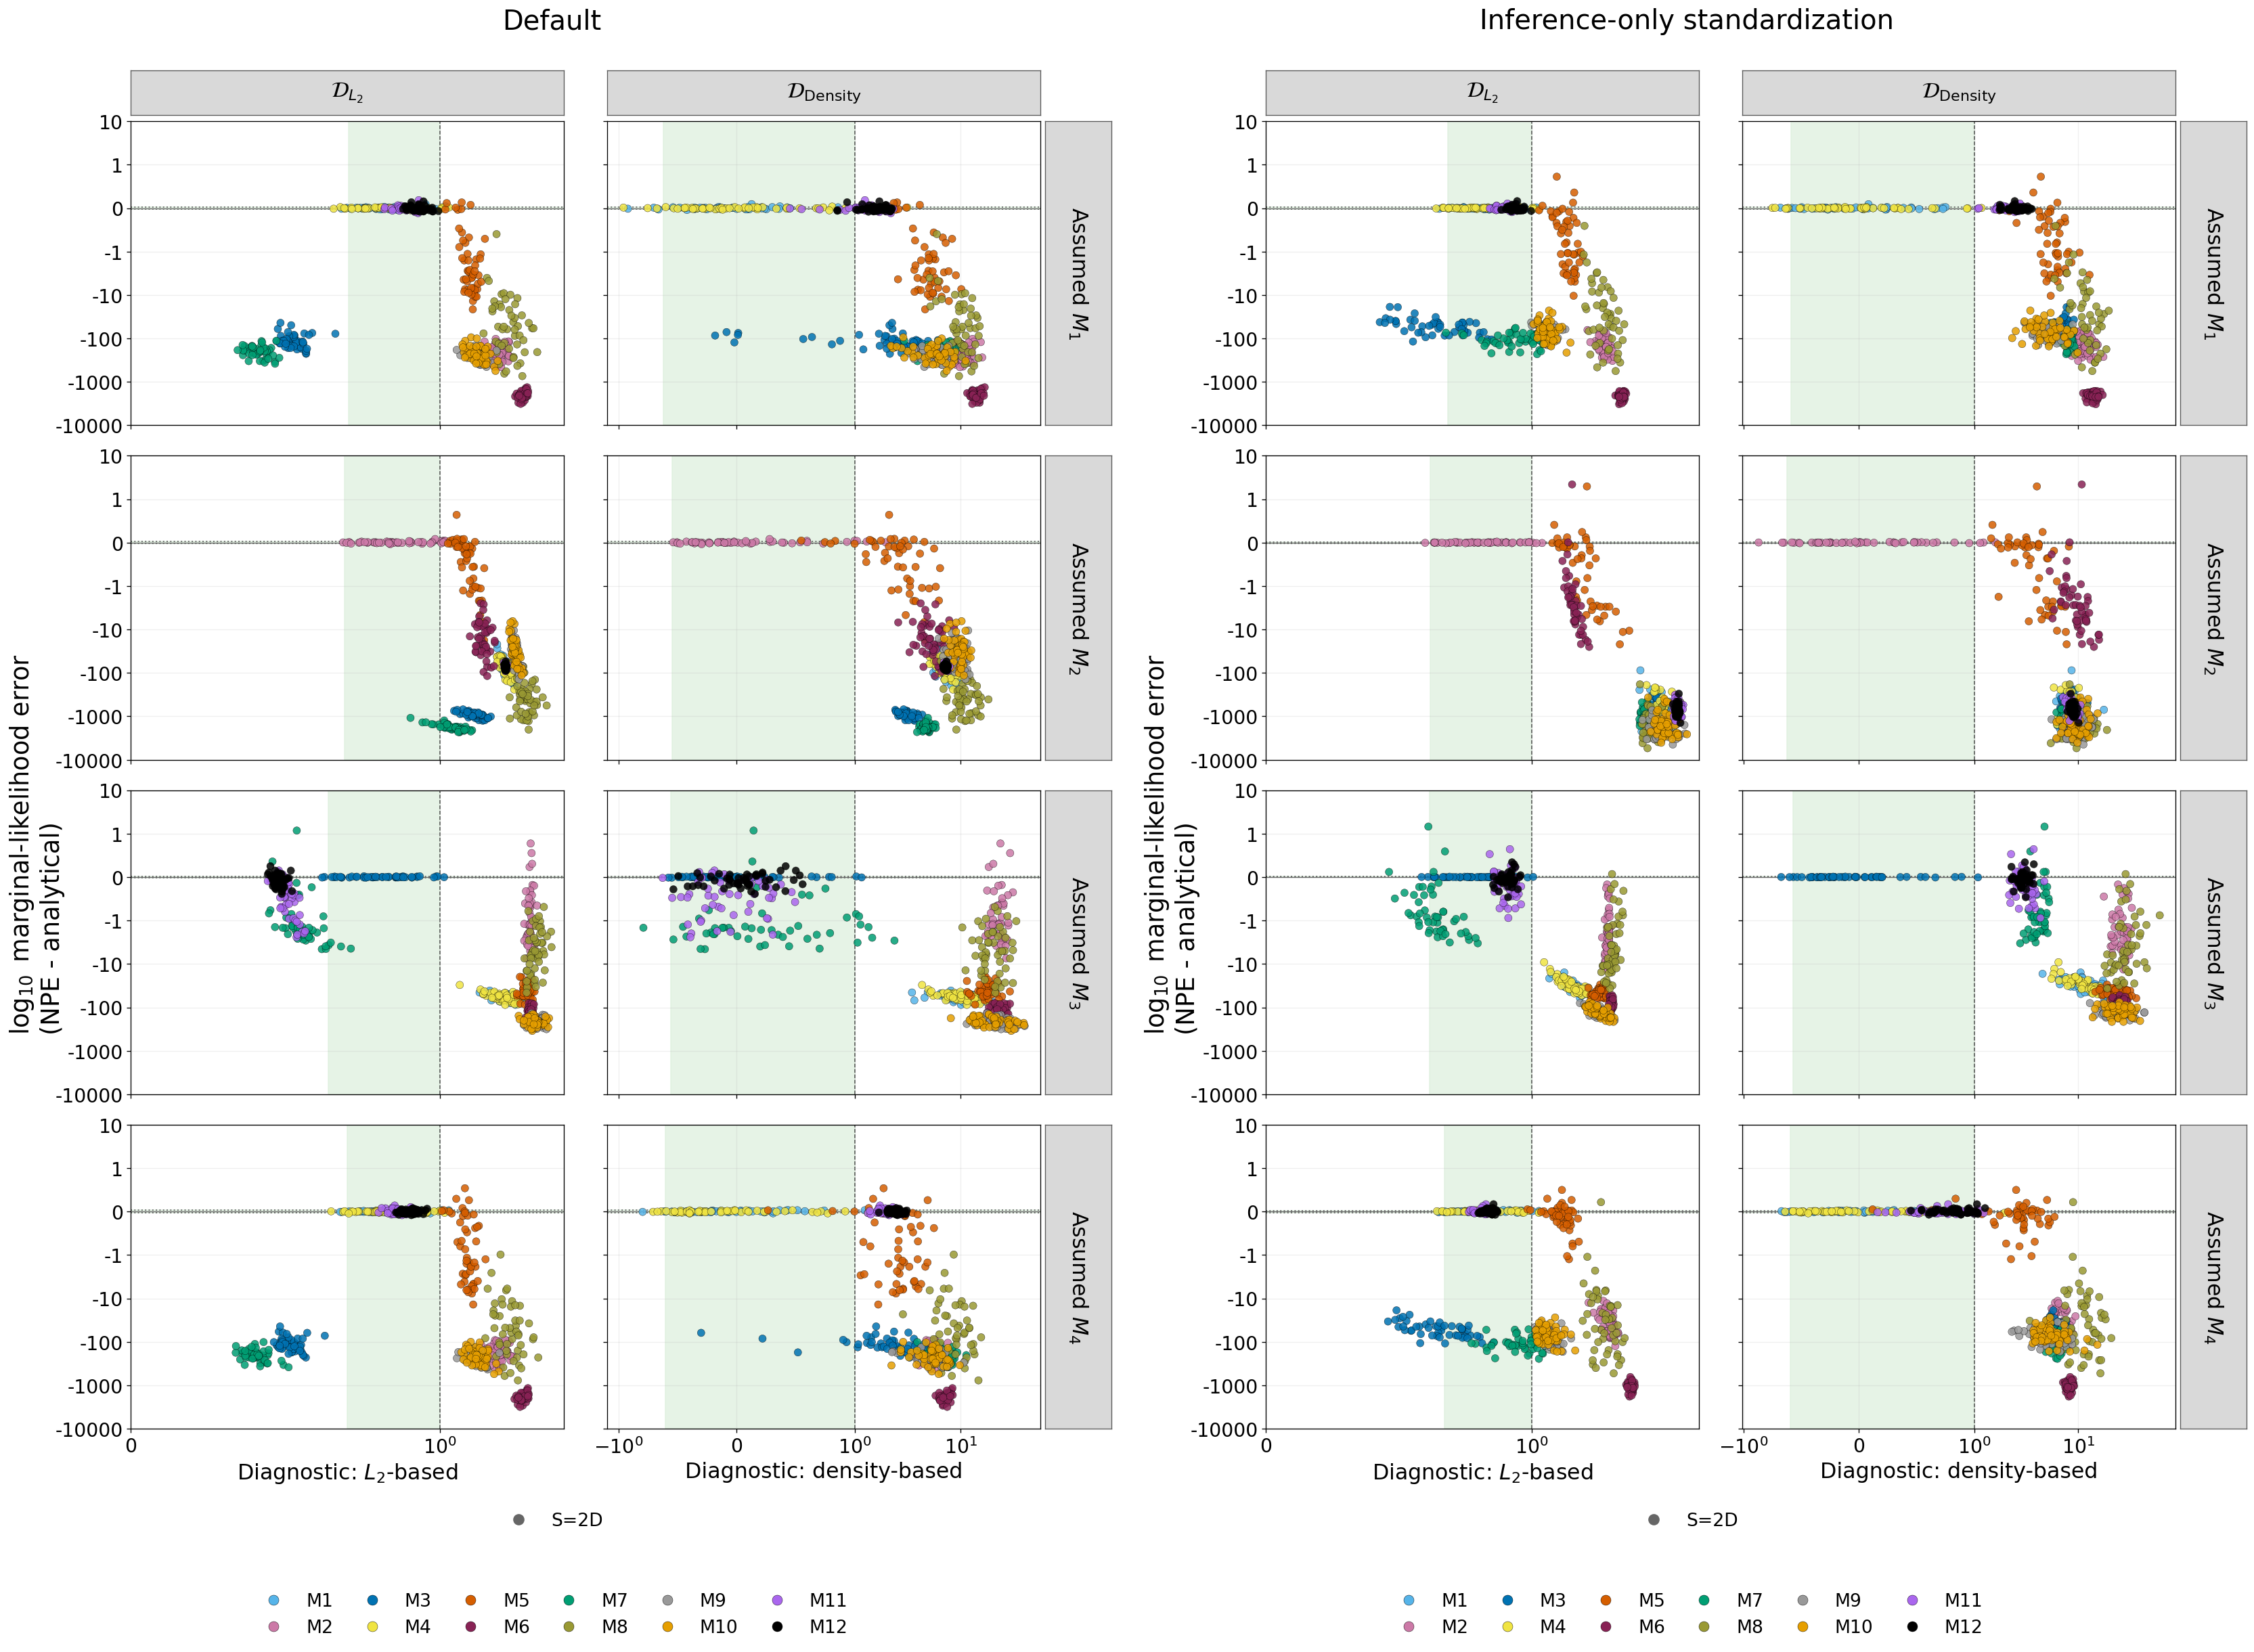

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/n100/standardization_s2d/default_vs_inference_only_logml.png


In [8]:
show_pair("Inference-only standardization", "logml", summary_dim=40)

### PMP error

#### Default vs Inference-only standardization

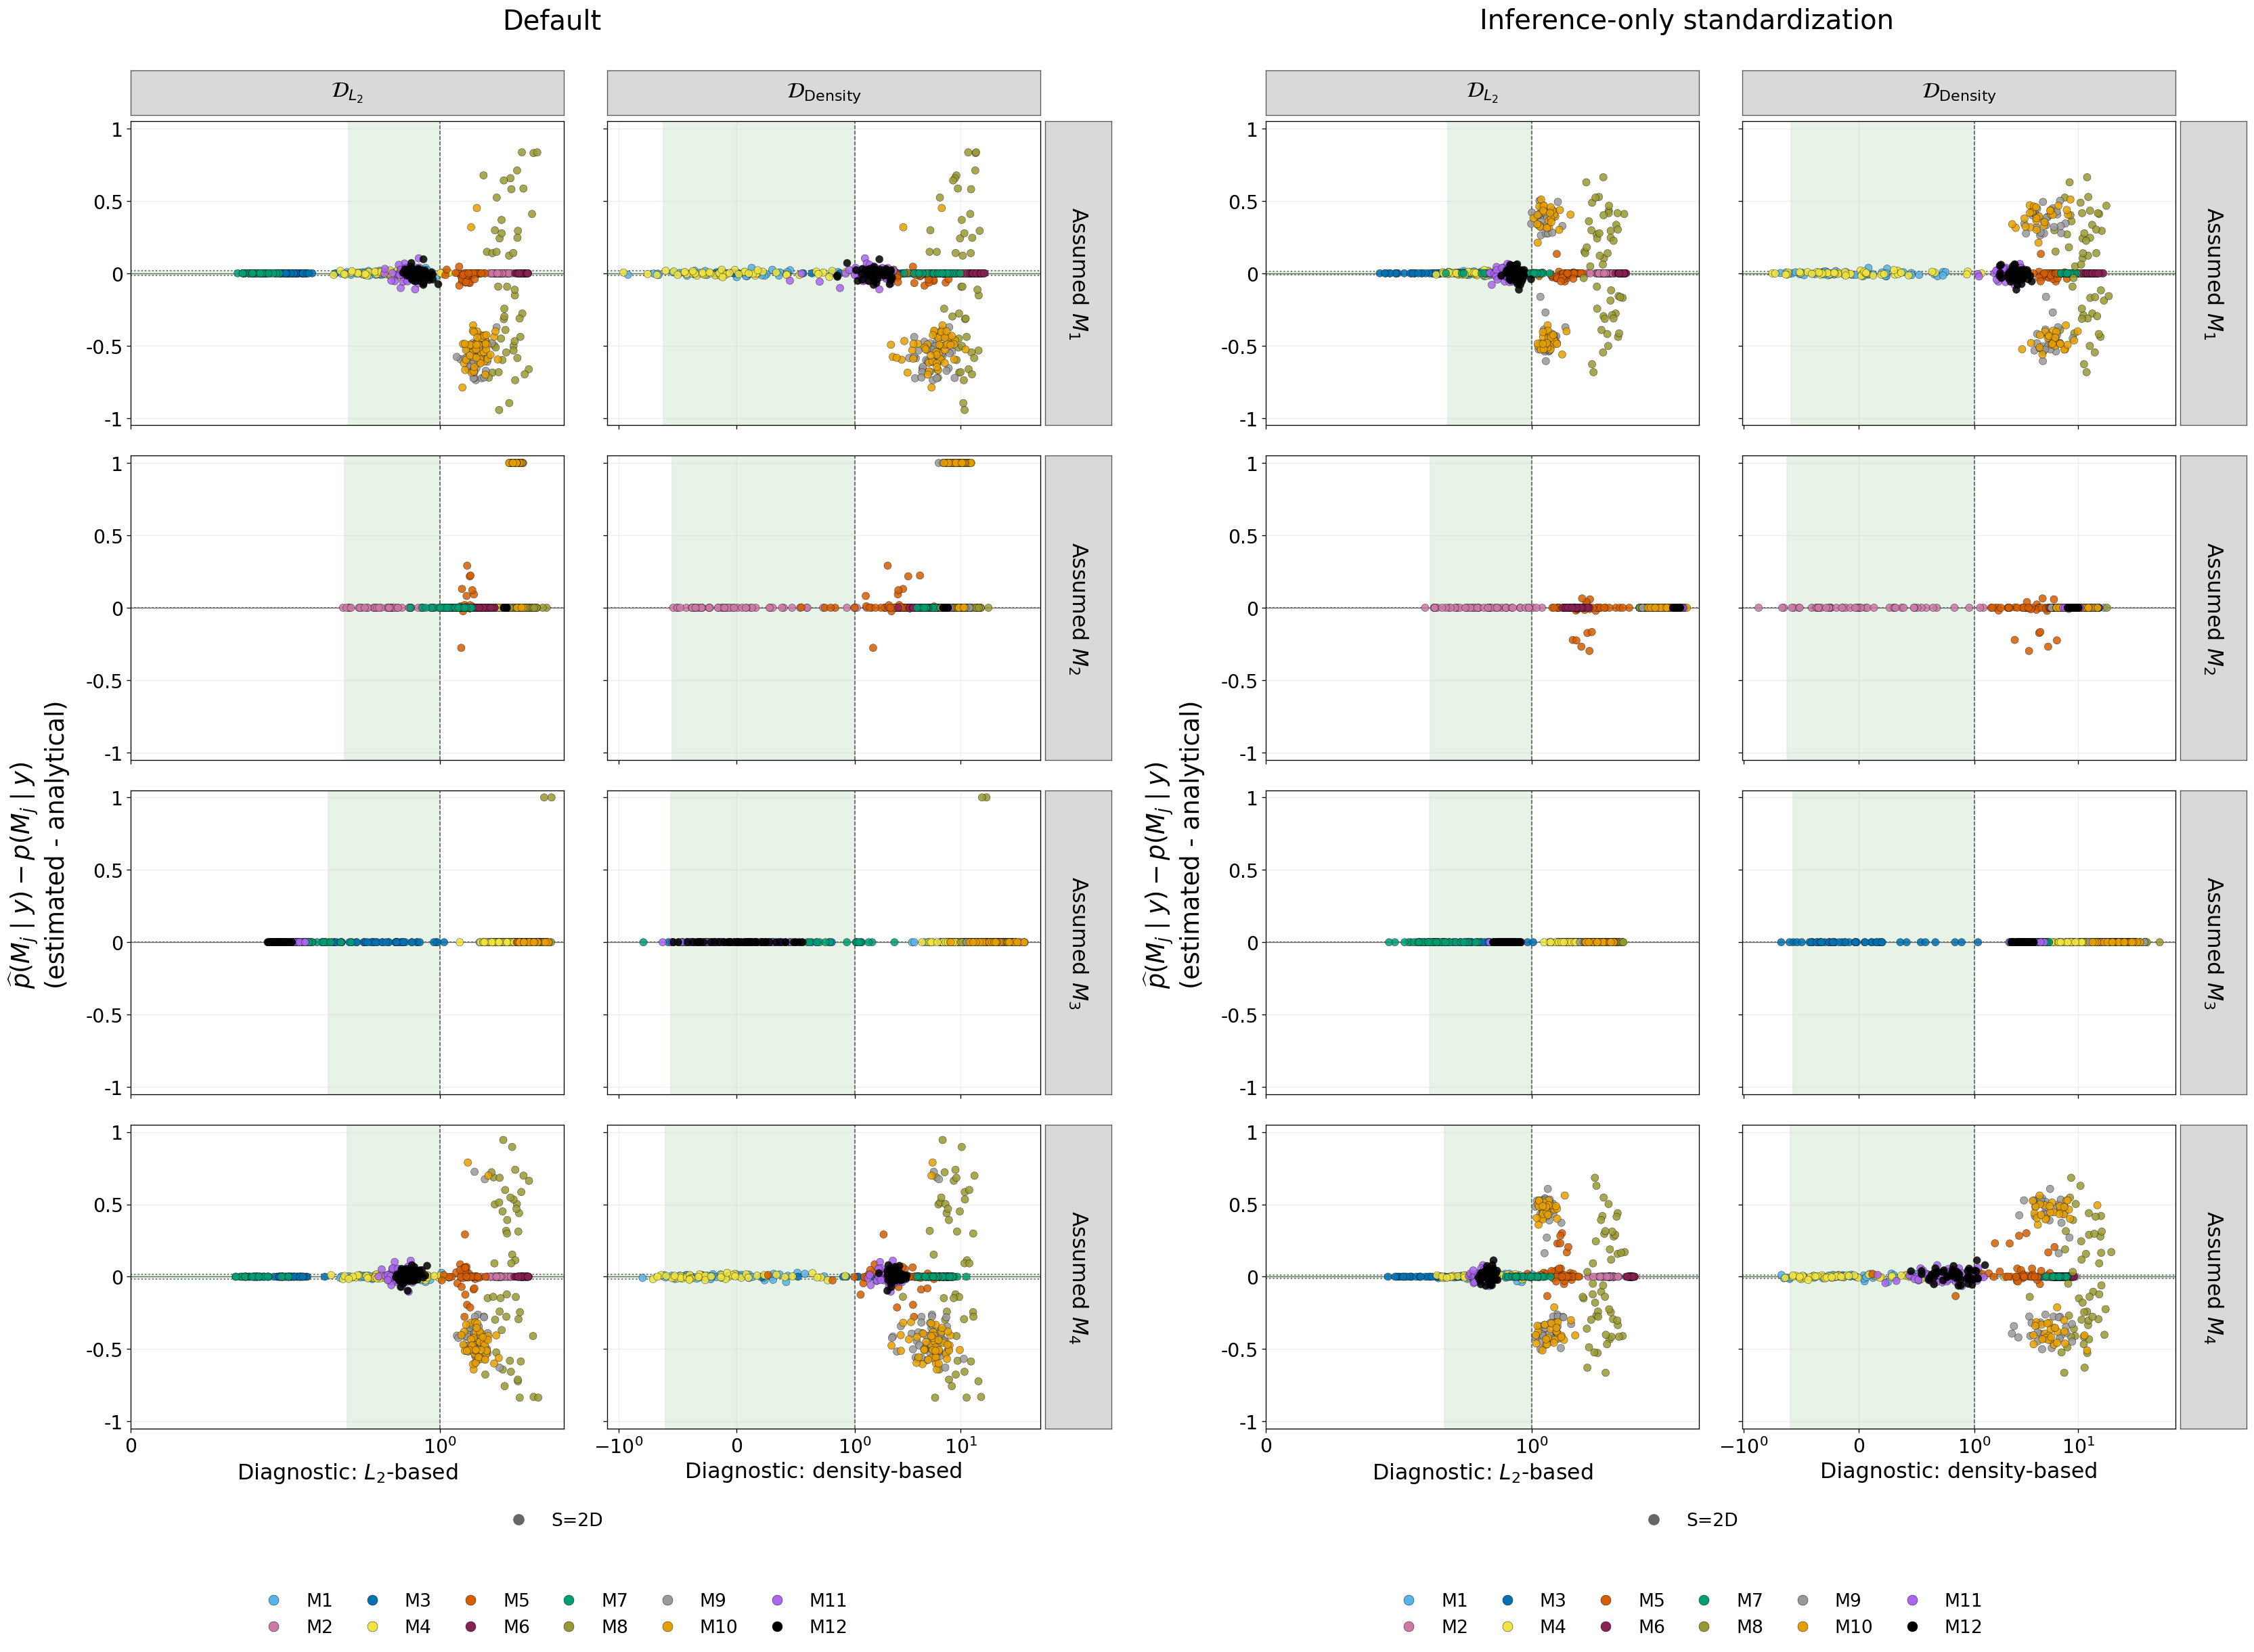

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/n100/standardization_s2d/default_vs_inference_only_pmp.png


In [9]:
show_pair("Inference-only standardization", "pmp", summary_dim=40)